# KDD Project: Mall Customer Segmentation

## Project Objective

The goal of this project is to identify groups of mall customers based on annual income and spending score using the K-means clustering algorithm. The project follows the five stages of Knowledge Discovery in Databases (KDD).

## Research Question

Can customers be grouped into meaningful segments based on their annual income and spending score?

## Dataset

**Dataset name:** Mall Customer Segmentation Data

**Source:** [Kaggle — Mall Customer Segmentation Data](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

The dataset contains customer information, including customer ID, gender, age, annual income, and spending score. The spending score is assigned by the mall based on customer behavior and spending patterns. <Cite refs={["turn327830search6","turn327830search0"]}/>

## KDD Methodology

1. **Selection:** Select the dataset and relevant customer features.
2. **Preprocessing:** Inspect data quality and address missing or duplicate records if necessary.
3. **Transformation:** Prepare and scale the features for clustering.
4. **Data Mining:** Apply K-means clustering and investigate an appropriate number of clusters.
5. **Interpretation and Evaluation:** Analyze the customer segments, visualize the results, and discuss potential business uses and limitations.

## Stage 1: Selection

The Mall Customer Segmentation dataset was selected because it contains customer demographic information, annual income, and a spending score. The analysis will focus on annual income and spending score to discover customer groups.

Customer ID will be used only to identify records, not as a clustering feature. The dataset will be inspected before any preprocessing or modeling is performed.

In [1]:
# KDD - Stage 1: Selection
# Upload and inspect the Mall Customers dataset.

import pandas as pd
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the first five rows
display(df.head())

# Inspect the dataset size
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Inspect data types and non-null values
print("\nDataset information:")
df.info()

Saving Mall_Customers.csv to Mall_Customers.csv


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## Stage 2: Preprocessing

The dataset was inspected to check for missing values, duplicate records, and duplicate customer IDs. These checks help identify data quality issues before clustering.

The dataset contains five columns: CustomerID, Gender, Age, Annual Income (k$), and Spending Score (1-100). This project will focus on annual income and spending score. CustomerID will not be used as a clustering feature because it identifies customers rather than describing their spending behavior.

In [2]:
# KDD - Stage 2: Preprocessing

# Check for missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check for completely duplicated rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check for duplicate customer IDs
print("\nNumber of duplicate CustomerIDs:")
print(df["CustomerID"].duplicated().sum())

# Check the data types
print("\nData types:")
print(df.dtypes)

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Number of duplicate rows:
0

Number of duplicate CustomerIDs:
0

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


## Stage 3: Transformation

For this project, Annual Income (k$) and Spending Score (1-100) were selected as the two clustering features. CustomerID was excluded because it is only an identifier, and Gender and Age were excluded to keep the analysis focused on income and spending behavior.

The two selected features will be standardized before applying K-means. Standardization puts the features on a comparable scale, helping prevent differences in their numerical ranges from disproportionately influencing the clustering results.

In [3]:
# KDD - Stage 3: Transformation

from sklearn.preprocessing import StandardScaler

# Select the two features for clustering
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

# Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display the original and transformed data
print("Original selected features:")
display(X.head())

print("First five standardized rows:")
display(pd.DataFrame(X_scaled, columns=features).head())

print("\nStandardized feature means:")
print(pd.DataFrame(X_scaled, columns=features).mean().round(3))

print("\nStandardized feature standard deviations:")
print(pd.DataFrame(X_scaled, columns=features).std(ddof=0).round(3))

Original selected features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


First five standardized rows:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Standardized feature means:
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standardized feature standard deviations:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


## Stage 4: Data Mining

K-means clustering will be used to group customers based on annual income and spending score. Because the dataset does not provide predefined customer segment labels, this is an unsupervised learning task.

To help choose the number of clusters, the analysis will compare K-means inertia using the elbow method and silhouette scores for different values of k. Inertia measures how close customers are to their assigned cluster centers, while the silhouette score measures how well-separated the clusters are. These measures will help guide the selection of a suitable number of customer segments.

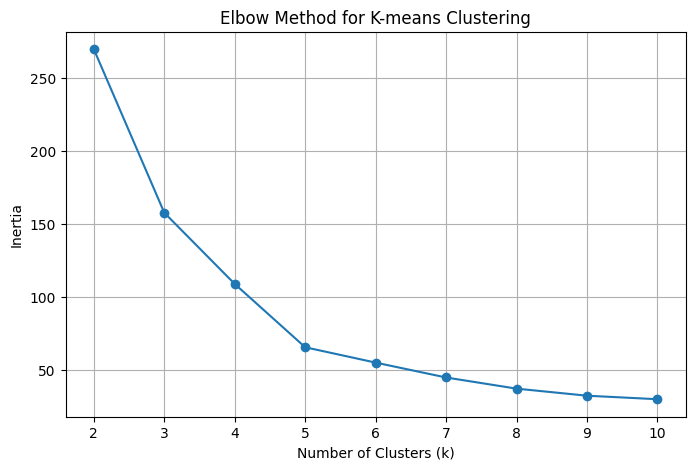

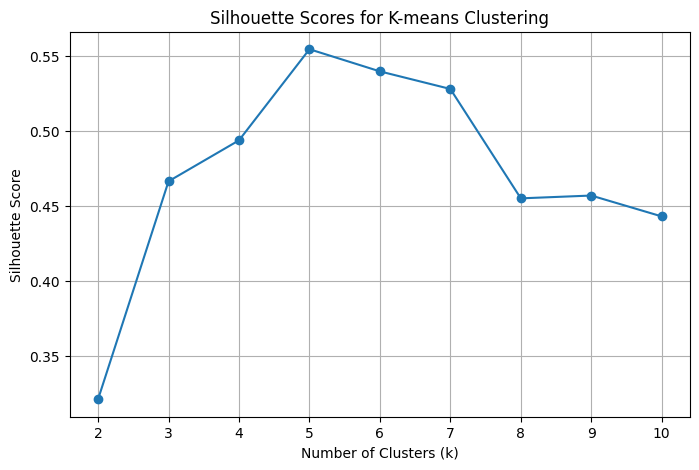

,Number of Clusters (k),Inertia,Silhouette Score
0,2,269.691,0.321
1,3,157.704,0.467
2,4,108.921,0.494
3,5,65.568,0.555
4,6,55.057,0.540
5,7,44.865,0.528
6,8,37.228,0.455
7,9,32.392,0.457
8,10,29.982,0.443


In [4]:
# KDD - Stage 4: Find a suitable number of clusters

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, cluster_labels)
    )

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for K-means Clustering")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.title("Silhouette Scores for K-means Clustering")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Display the results for comparison
results_df = pd.DataFrame({
    "Number of Clusters (k)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results_df.round(3))

### Selecting the Number of Clusters

The elbow method and silhouette score were used to compare cluster counts from 2 through 10. The silhouette score was highest at five clusters, with a score of 0.555. The elbow plot also shows that the reduction in inertia becomes more gradual after approximately five clusters.

Based on these results, five clusters were selected for the initial K-means model. This choice will be evaluated further by examining cluster sizes, cluster centers, and the distribution of customers in the income-spending plot.

In [5]:
# KDD - Stage 4: Fit the selected K-means model

# Fit K-means using five clusters
kmeans_final = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans_final.fit_predict(X_scaled)

# Display the number of customers in each cluster
print("Number of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# Calculate average customer characteristics for each cluster
cluster_profiles = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean"
}).round(2)

print("\nAverage characteristics of each cluster:")
display(cluster_profiles)

# Convert cluster centers back to the original feature scale
centers_original = scaler.inverse_transform(kmeans_final.cluster_centers_)

centers_df = pd.DataFrame(
    centers_original,
    columns=features
).round(2)

print("\nCluster centers in original units:")
display(centers_df)

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Average characteristics of each cluster:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91



Cluster centers in original units:


,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


# Interpretation of Five Customer Clusters

The model grouped all 200 customers into five clusters. Here is what the average income and spending scores suggest.
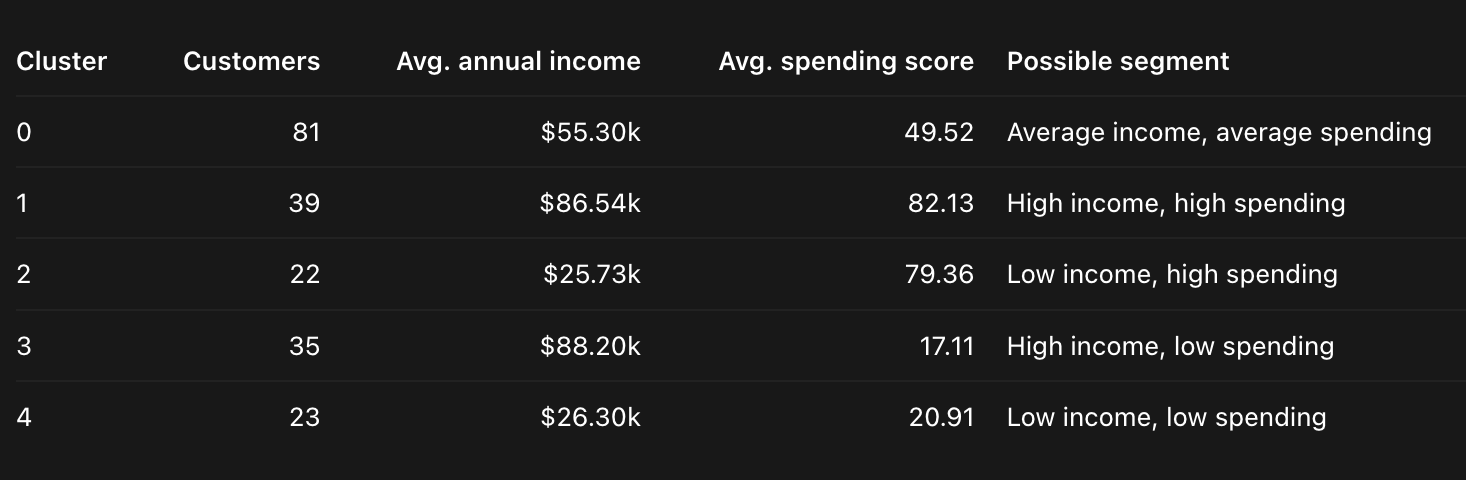
Note: These labels are interpretations based on cluster averages, not labels provided by the dataset. The income values are reported in thousands of dollars.

The clusters reveal five potentially useful customer groups:
- Cluster 0: The largest group, with relatively average income and spending.
- Cluster 1: Higher-income customers with high spending scores; potentially valuable for premium offers.
- Cluster 2: Lower-income customers with high spending scores; potentially responsive to affordable promotions.
- Cluster 3: Higher-income customers with low spending scores; worth investigating for reasons they spend less.
- Cluster 4: Lower-income customers with low spending scores; budget-friendly offers may be more appropriate.

# Stage 4: Visualizing the Customer Segments

A scatter plot will be used to visualize the five clusters. Each point represents a customer, positioned according to annual income and spending score. Different colors represent the assigned clusters, and the cluster centers show the average location of each group.

This visualization helps assess whether the identified customer segments are distinct and how they differ in income and spending behavior.

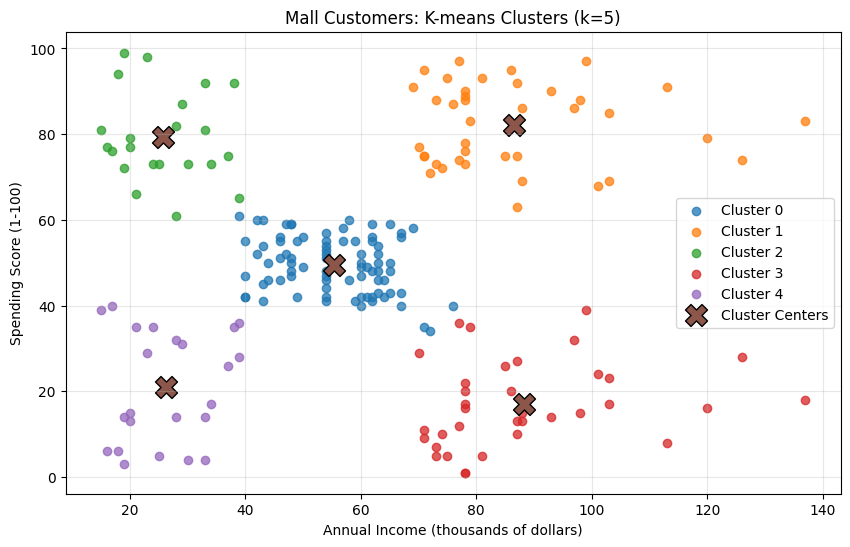

In [6]:
# KDD - Stage 4: Visualize the customer clusters

plt.figure(figsize=(10, 6))

for cluster_id in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster_id]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster_id}",
        alpha=0.75
    )

# Plot the cluster centers in the original feature scale
plt.scatter(
    centers_df["Annual Income (k$)"],
    centers_df["Spending Score (1-100)"],
    marker="X",
    s=250,
    edgecolors="black",
    label="Cluster Centers"
)

plt.title("Mall Customers: K-means Clusters (k=5)")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Stage 5: Interpretation and Evaluation

The final K-means model grouped the 200 customers into five clusters based on annual income and spending score. The scatter plot shows five recognizable groups, and the cluster centers represent the average income and spending score of each group.

- **Cluster 0:** Average income and average spending.
- **Cluster 1:** High income and high spending.
- **Cluster 2:** Low income and high spending.
- **Cluster 3:** High income and low spending.
- **Cluster 4:** Low income and low spending.

These segments could help a mall explore different marketing strategies. For example, high-income, high-spending customers could be considered for premium promotions, while customers with high spending scores and lower incomes might respond to affordable offers.

The five-cluster model achieved a silhouette score of 0.555, the highest among the tested values of two through ten clusters. This suggests reasonably well-separated clusters for this dataset, although the results do not prove that five clusters are the only valid choice.

The analysis has limitations. It uses only annual income and spending score, excludes age and gender from clustering, and identifies patterns rather than explaining why customers behave a certain way. The findings should be treated as exploratory and would benefit from further validation before real marketing decisions are made.

In [7]:
# KDD - Save the final clustering results

from google.colab import files

# Save customer records with their assigned cluster
output_file = "kdd_mall_customer_clusters.csv"
df.to_csv(output_file, index=False)

print("Saved file:", output_file)
print("Total customers:", len(df))
print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

# Download the CSV to your computer
files.download(output_file)

Saved file: kdd_mall_customer_clusters.csv
Total customers: 200

Cluster counts:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# Final evaluation metric

from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(X_scaled, df["Cluster"])

print(f"Number of clusters: {kmeans_final.n_clusters}")
print(f"Final silhouette score: {final_silhouette:.3f}")
print(f"Customers evaluated: {len(df)}")

Number of clusters: 5
Final silhouette score: 0.555
Customers evaluated: 200
